# Grover's Search Algorithm with Qiskit (4 qubits)

Grover's algorithm finds a marked item in an **unstructured** search space of N items in **O(√N)** oracle queries, versus **O(N)** classically: a quadratic speedup.

With **4 qubits**, the search space is N = 2⁴ = **16** states, |0000⟩ to |1111⟩. Set `TARGET` below to any value from 0 to 15.

**Circuit pipeline:**
```
|0000⟩  →  H⊗4 (uniform superposition)  →  [ Oracle → Diffuser ] × K  →  Measure
```

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

TARGET   = 2              # value to search for, 0..15
N_QUBITS = 4
N        = 2 ** N_QUBITS

print(f"Search value: {TARGET}  ->  |{TARGET:04b}⟩   (search space N = {N})")

Search value: 2  ->  |0010⟩   (search space N = 16)


---
## Oracle

A **phase oracle** flips the sign of the target state's amplitude and leaves every other state alone:

1. Apply X to every qubit that is **0** in the target, so the target becomes |1111⟩
2. Multi-controlled Z (built as H · MCX · H on the last qubit) flips the phase of |1111⟩
3. Undo the X gates

Qubit `q[i]` holds bit *i* of the target (q0 = least significant bit), matching Qiskit's little-endian convention.

In [2]:
def mcz(qc, qubits):
    """Multi-controlled Z: phase -1 on |11...1>."""
    qc.h(qubits[-1])
    qc.mcx(qubits[:-1], qubits[-1])
    qc.h(qubits[-1])


def build_oracle(qc, qubits, target):
    zero_bits = [q for i, q in enumerate(qubits) if not (target >> i) & 1]
    if zero_bits:
        qc.x(zero_bits)
    mcz(qc, qubits)
    if zero_bits:
        qc.x(zero_bits)


flips = [f"q{i}" for i in range(N_QUBITS) if not (TARGET >> i) & 1]
print(f"Oracle for |{TARGET:04b}⟩ flips {', '.join(flips)} before the MCZ")

Oracle for |0010⟩ flips q0, q2, q3 before the MCZ


---
## Diffuser

The diffusion operator performs **inversion about the mean**:

$$D = H^{\otimes n}\,(2|0⟩⟨0| - I)\,H^{\otimes n}$$

After the oracle makes the target amplitude negative, reflecting everything about the average boosts the target and shrinks the rest.

In [3]:
def build_diffuser(qc, qubits):
    qc.h(qubits)
    qc.x(qubits)
    mcz(qc, qubits)
    qc.x(qubits)
    qc.h(qubits)

---
## Full circuit

Each Grover iteration rotates the state by $2\theta$ toward the target, where $\sin\theta = 1/\sqrt{N}$. The best number of iterations is

$$K_{opt} = \left\lfloor \frac{\pi}{4\theta} \right\rfloor = 3 \quad \text{for } N = 16$$

K_opt = 3   depth = 38   qubits = 4


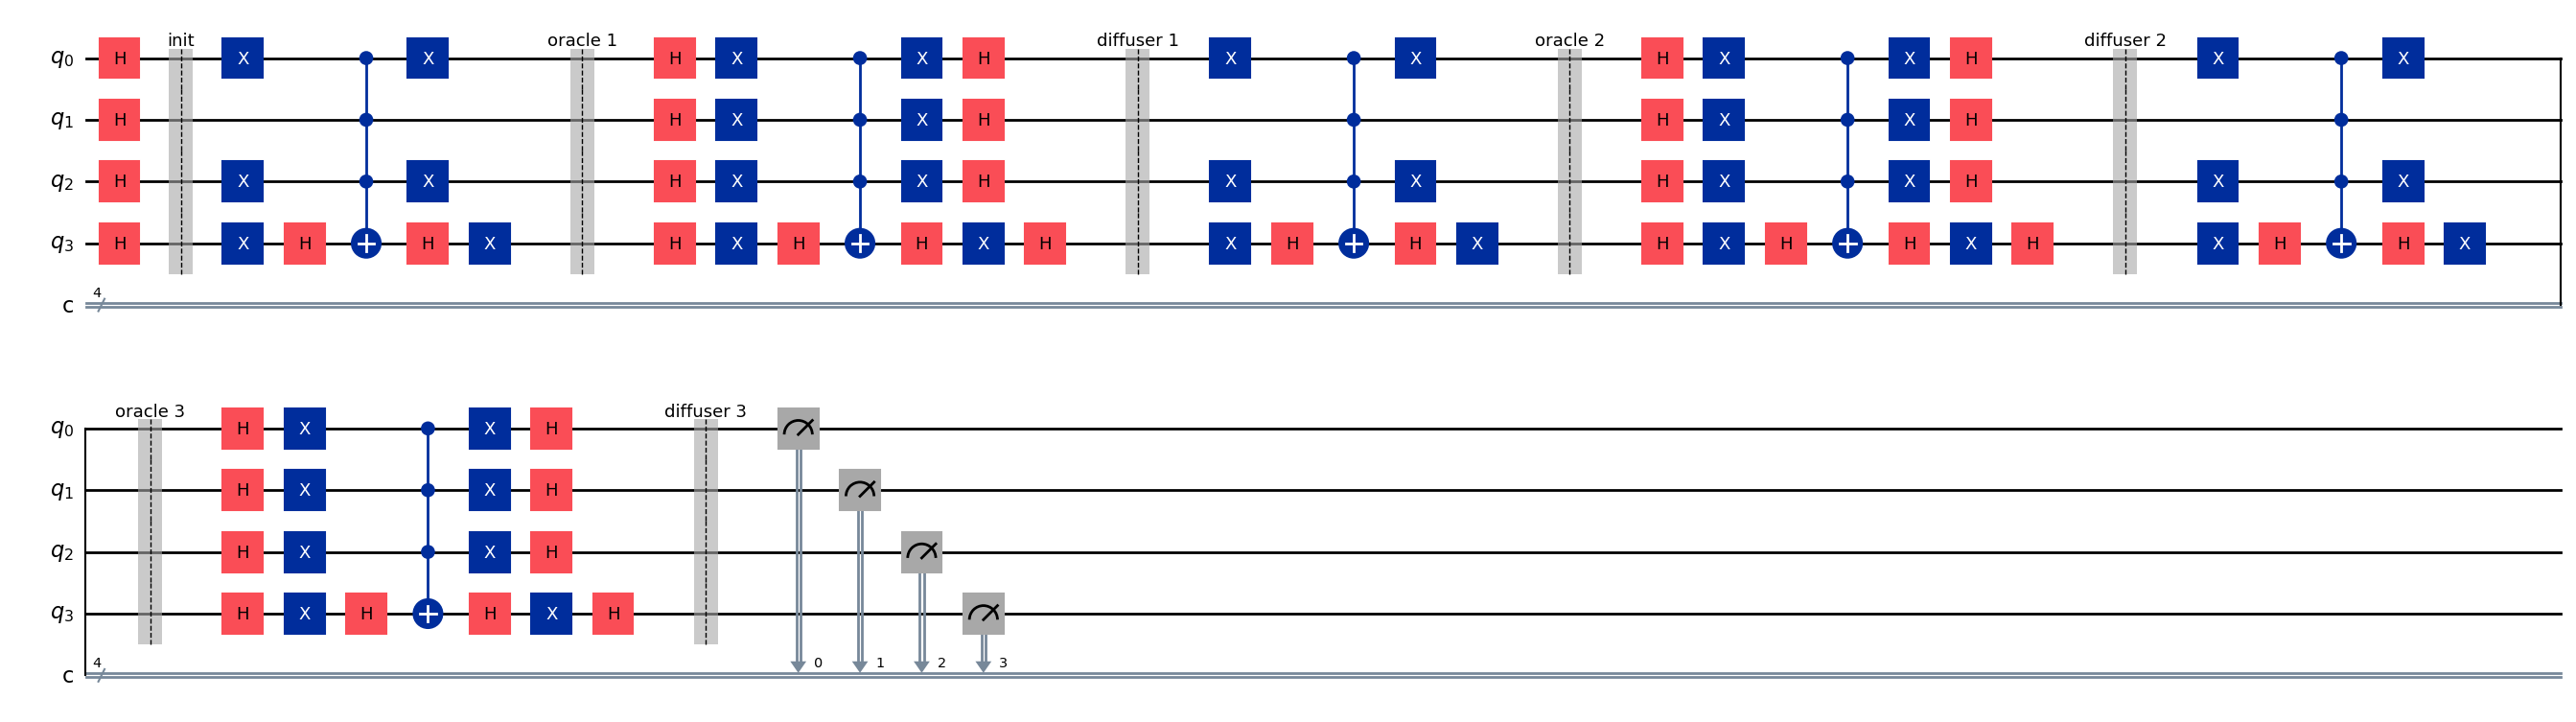

In [4]:
def build_grover_circuit(target, n_qubits=N_QUBITS, iterations=1):
    q = QuantumRegister(n_qubits, "q")
    c = ClassicalRegister(n_qubits, "c")
    qc = QuantumCircuit(q, c)

    qc.h(q)
    qc.barrier(label="init")
    for k in range(1, iterations + 1):
        build_oracle(qc, list(q), target)
        qc.barrier(label=f"oracle {k}")
        build_diffuser(qc, list(q))
        qc.barrier(label=f"diffuser {k}")
    qc.measure(q, c)
    return qc


THETA = math.asin(1 / math.sqrt(N))
K_OPT = math.floor(math.pi / (4 * THETA))

qc = build_grover_circuit(TARGET, iterations=K_OPT)
print(f"K_opt = {K_OPT}   depth = {qc.depth()}   qubits = {qc.num_qubits}")
fig = qc.draw("mpl", fold=40)
fig.savefig("../images/grover_circuit.png", dpi=130, bbox_inches="tight")
fig

---
## Simulation

In [5]:
sim = AerSimulator()


def run(circuit, shots=1000):
    return sim.run(circuit, shots=shots).result().get_counts()


SHOTS = 1000
counts = run(qc, SHOTS)

# Qiskit bitstrings are already little-endian (c3 c2 c1 c0), so int(bits, 2) is the value
probs = np.zeros(N)
for bits, cnt in counts.items():
    probs[int(bits, 2)] = cnt / SHOTS

for v in range(N):
    marker = "  <- TARGET" if v == TARGET else ""
    print(f"|{v:04b}⟩ ({v:2d})  {probs[v]:.3f}{marker}")
print(f"\nP(target) = {probs[TARGET]:.3f}")

|0000⟩ ( 0)  0.002
|0001⟩ ( 1)  0.000
|0010⟩ ( 2)  0.957  <- TARGET
|0011⟩ ( 3)  0.003
|0100⟩ ( 4)  0.007
|0101⟩ ( 5)  0.003
|0110⟩ ( 6)  0.003
|0111⟩ ( 7)  0.002
|1000⟩ ( 8)  0.004
|1001⟩ ( 9)  0.001
|1010⟩ (10)  0.002
|1011⟩ (11)  0.007
|1100⟩ (12)  0.001
|1101⟩ (13)  0.002
|1110⟩ (14)  0.003
|1111⟩ (15)  0.003

P(target) = 0.957


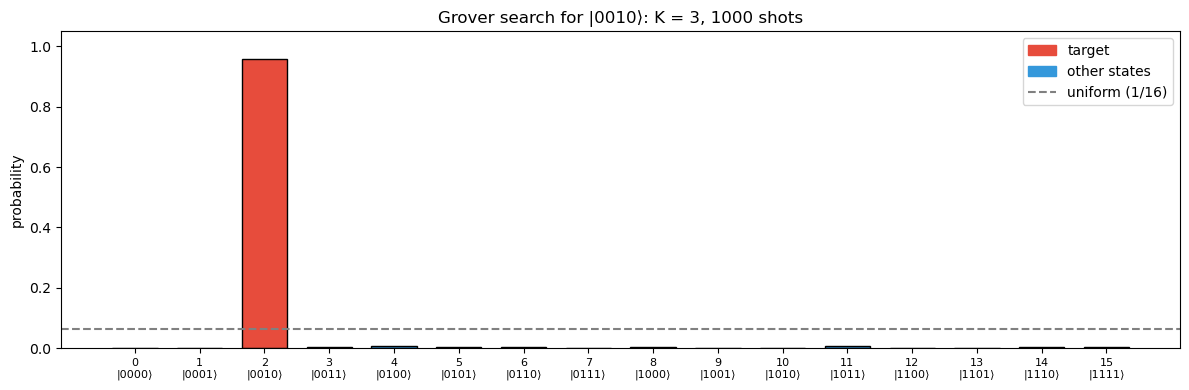

In [6]:
colors = ["#e74c3c" if v == TARGET else "#3498db" for v in range(N)]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(N), probs, color=colors, edgecolor="black", width=0.7)
ax.axhline(1 / N, color="gray", ls="--", label=f"uniform (1/{N})")
ax.set_xticks(range(N), [f"{v}\n|{v:04b}⟩" for v in range(N)], fontsize=8)
ax.set_ylabel("probability")
ax.set_ylim(0, 1.05)
ax.set_title(f"Grover search for |{TARGET:04b}⟩: K = {K_OPT}, {SHOTS} shots")
ax.legend(handles=[Patch(color="#e74c3c", label="target"),
                   Patch(color="#3498db", label="other states"),
                   plt.Line2D([0], [0], color="gray", ls="--", label=f"uniform (1/{N})")])
plt.tight_layout()
plt.savefig("../images/grover_histogram.png", dpi=130)
plt.show()

---
## Performance analysis: theory vs. simulation

Theoretical success probability after K iterations:

$$P(K) = \sin^2\big((2K+1)\,\theta\big), \qquad \theta = \arcsin\frac{1}{\sqrt{N}}$$

Empirical probability = mean over 10 trials × 1000 shots.

In [7]:
TRIALS, K_MAX = 10, 6


def theoretical_probability(K):
    return math.sin((2 * K + 1) * THETA) ** 2


def empirical_probability(K, trials=TRIALS, shots=SHOTS):
    target_bits = f"{TARGET:0{N_QUBITS}b}"
    qc_k = build_grover_circuit(TARGET, iterations=K)
    return float(np.mean([run(qc_k, shots).get(target_bits, 0) / shots for _ in range(trials)]))


results = []
print(f"{'K':>2}  {'theory':>7}  {'empirical':>9}  {'% error':>8}")
for K in range(1, K_MAX + 1):
    th, emp = theoretical_probability(K), empirical_probability(K)
    err = (emp - th) / th * 100
    results.append((K, th, emp, err))
    print(f"{K:>2}  {th:7.4f}  {emp:9.4f}  {err:7.2f}%" + ("  <- optimal" if K == K_OPT else ""))

 K   theory  empirical   % error
 1   0.4727     0.4719    -0.16%
 2   0.9084     0.9084    -0.01%


 3   0.9613     0.9652     0.40%  <- optimal
 4   0.5817     0.5787    -0.52%
 5   0.1255     0.1247    -0.63%
 6   0.0204     0.0194    -4.81%


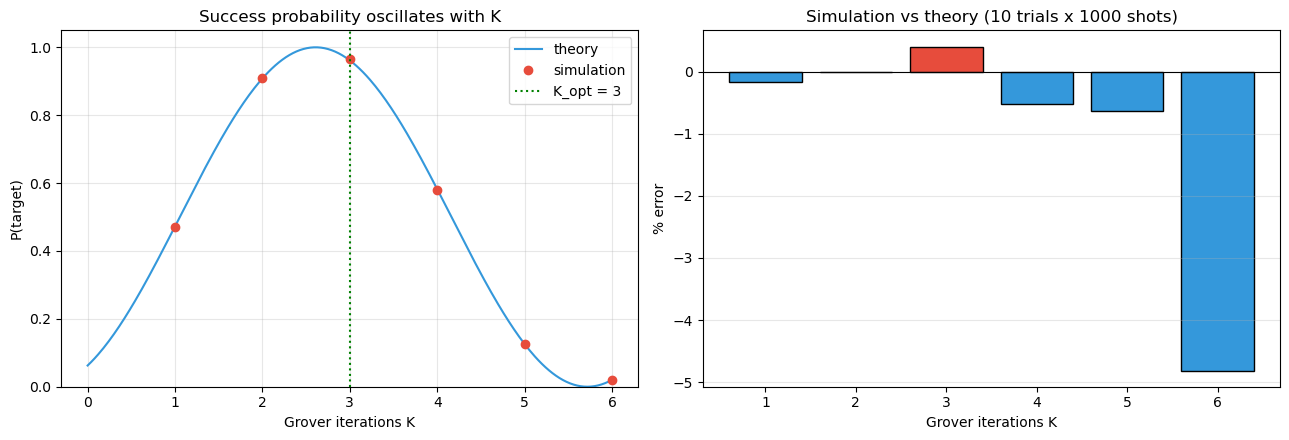

In [8]:
Ks, th, emp, err = zip(*results)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ks_fine = np.linspace(0, K_MAX, 300)
ax1.plot(ks_fine, np.sin((2 * ks_fine + 1) * THETA) ** 2, color="#3498db", label="theory")
ax1.plot(Ks, emp, "o", color="#e74c3c", label="simulation")
ax1.axvline(K_OPT, color="green", ls=":", label=f"K_opt = {K_OPT}")
ax1.set(xlabel="Grover iterations K", ylabel="P(target)", ylim=(0, 1.05),
        title="Success probability oscillates with K")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.bar(Ks, err, color=["#e74c3c" if k == K_OPT else "#3498db" for k in Ks], edgecolor="black")
ax2.axhline(0, color="black", lw=0.8)
ax2.set(xlabel="Grover iterations K", ylabel="% error",
        title=f"Simulation vs theory ({TRIALS} trials x {SHOTS} shots)")
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("../images/grover_performance.png", dpi=130)
plt.show()

---
## Discussion

- **K = 3 is optimal for N = 16.** Success probability peaks at ≈ 96%. Running more iterations *over-rotates* past the target and the probability drops: Grover's algorithm is periodic in K, not monotonic.
- **Speedup:** classical search needs ~N/2 = 8 lookups on average; Grover needs 3 oracle calls. For N = 2⁶⁴ that's ~10¹⁹ vs ~4·10⁹.
- **Error source:** the Aer simulator is noiseless, so differences from theory are pure shot noise (~1/√shots). The % error looks large at K values where the theoretical probability itself is tiny.